# 09 - An EV fleet with mobility and smart charging

Charging load is set by when cars arrive, how far they drive, and when their owners need
them again. A fleet model that starts every car at full charge, or that charges every car
the moment it is plugged in, misses the shape of the problem. This notebook builds an
`EVFleet` vectorized container for 5,000 cars over one week, with:

- **Mobility**: each car has a departure hour, an arrival hour and a daily driving distance,
  drawn from distributions. Weekdays and weekends use different distributions (the day index
  decides which one applies).
- **Consumption**: kWh per 100 km, raised in cold weather.
- **Charging**: a CC-CV taper (power falls above 80 % state of charge) on each car's charger.
- **Policies**: `immediate`, `tou` (charge only in cheap-price hours) and `smart`
  (latest-start-time deadline scheduling, plus charging in cheap hours).
- **A shared grid limit**: the aggregate charging demand is scaled down proportionally when it
  exceeds the transformer limit.
- **Price input**: a time-of-use price drives the policy choice and the cost accounting.

The same population (same random seed) is run under the three policies, so the differences
come from the policy, not from the sampled cars.

## 1. The model

**Schedules**. Car *i* has, for each day *d*, one departure at `dep[i,d]` and one arrival at
`arr[i,d]` (the day's driving is lumped into one trip). The car is plugged in between
arrival and the next departure. Weekdays: departure about 07:30 and arrival about 18:00.
Weekends: later departures and more spread in the arrival time.

**Energy at departure**. The trip energy is drawn from the battery when the car leaves:
`E_trip = km * cons_i / 100 * f_cold(T_amb)`, with `f_cold = 1 + 0.012 * max(0, 20 - T_amb)`
(capped at 1.6). The required state of charge at departure is `target_soc` (80 % in this notebook).
A car that leaves below the target is counted as a short departure, and the missing energy
`(target - soc) * capacity` is accumulated as the unmet-departure energy.

**Charging**. A plugged car draws up to `P_max = P_charger * taper(SoC)` with a CC-CV taper
(`taper`: 1.0 up to 80 % SoC, 0.5 at 90 %, 0.15 at 100 %). Charger efficiency is 92 %. The
policies decide which plugged cars charge in a step:

| Policy | Charges when | Stops at |
|---|---|---|
| `immediate` | plugged in | 100 % |
| `tou` | plugged in and the price is cheap (at or below `price_cheap`) | 100 % |
| `smart` | the latest start time has passed (`t >= dep_next - E_need / P_charger - margin`), or the price is cheap | the target SoC |

`latest_start` is the deadline rule: the latest moment a car can start at full power and still
reach the target before it leaves. `smart` charges to the target only, not to 100 %.

**Grid limit**. The requested powers are summed. If the sum exceeds `grid_limit_kw`, every car's
power is multiplied by the same factor, so the transformer limit is respected and the cars share
the shortfall equally.

**Outputs**: total charging power, number of plugged cars, mean SoC, unmet departure energy,
number of short departures, departures, and cumulative energy cost.

In [2]:
import math
from typing import Dict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from energysim import world
from energysim.container import VectorizedContainerAdapter
from energysim.models.common import Curve1D

SEED = 7
N_EVS = 5000
DAYS = 7
DT_S = 900.0
GRID_LIMIT_KW = 8000.0            # aggregate transformer limit for the feeder serving these cars
POLICIES = ("immediate", "tou", "smart")
WEEK_S = DAYS * 86400


def draw_population(n: int, days: int, seed: int) -> Dict[str, np.ndarray]:
    """Draw the cars and their schedules once, so every policy sees the same population."""
    rng = np.random.default_rng(seed)
    batt_kwh = rng.choice([40.0, 60.0, 75.0, 90.0], size=n, p=[0.25, 0.35, 0.25, 0.15])
    cons = np.clip(rng.normal(16.5, 2.0, n), 12.0, 24.0)                  # kWh per 100 km
    charger_kw = rng.choice([3.7, 7.4, 11.0], size=n, p=[0.35, 0.50, 0.15])
    soc0 = rng.uniform(0.35, 0.90, n)

    day = np.arange(days)
    weekday = (day % 7) < 5                                                # day 0 is a Monday
    dep_h = np.where(weekday, rng.normal(7.5, 0.8, (n, days)), rng.normal(10.0, 2.0, (n, days)))
    arr_h = np.where(weekday, rng.normal(18.0, 1.2, (n, days)), rng.normal(18.5, 2.5, (n, days)))
    dep_h = np.clip(dep_h, 5.0, 12.0)
    arr_h = np.clip(arr_h, dep_h + 4.0, 23.5)
    trip_km = np.clip(rng.lognormal(np.log(np.where(weekday, 30.0, 20.0)), 0.7, (n, days)), 2.0, 250.0)

    dep_s = day * 86400.0 + dep_h * 3600.0
    arr_s = day * 86400.0 + arr_h * 3600.0
    ev_t = np.stack([dep_s, arr_s], axis=2).reshape(n, 2 * days)          # dep0, arr0, dep1, arr1, ...
    return {
        "batt_kwh": batt_kwh, "cons": cons, "charger_kw": charger_kw, "soc0": soc0,
        "trip_km": trip_km, "ev_t": ev_t,
    }


def cold_factor(t_amb_degc):
    """Consumption multiplier: +1.2 % per K below 20 C, capped at 1.6."""
    return np.clip(1.0 + 0.012 * np.maximum(0.0, 20.0 - np.asarray(t_amb_degc, dtype=float)), 1.0, 1.6)


class EVFleet(VectorizedContainerAdapter):
    """N electric cars with mobility schedules, CC-CV charging and a shared grid limit."""

    units = {
        "t_amb_degc": "degC", "price_eur_kwh": "EUR/kWh",
        "p_charge_kw": "kW", "soc": "1", "plugged": "1", "cost_eur": "EUR",
        "unmet_kwh": "kWh", "n_short": "1", "n_dep": "1", "next_event": "1",
    }

    TAPER_SOC = [0.0, 0.8, 0.9, 1.0]
    TAPER_F = [1.0, 1.0, 0.5, 0.15]

    def __init__(self, name: str, pop: Dict[str, np.ndarray], policy: str = "smart",
                 grid_limit_kw: float = np.inf, target_soc: float = 0.8, soc_full: float = 1.0,
                 price_cheap: float = 0.15, charger_eff: float = 0.92, margin_h: float = 0.25,
                 step_size: float = DT_S):
        if policy not in POLICIES:
            raise ValueError(f"policy must be one of {POLICIES}, got {policy!r}")
        n = len(pop["batt_kwh"])
        super().__init__(name=name, size=n, step_size=step_size)
        self.policy = policy
        self.grid_limit_kw = float(grid_limit_kw)
        self.target_soc = float(target_soc)
        self.soc_full = float(soc_full)
        self.price_cheap = float(price_cheap)
        self.eff = float(charger_eff)
        self.margin_h = float(margin_h)

        self.batt = self._as_vector(pop["batt_kwh"], "batt_kwh")
        self.cons = self._as_vector(pop["cons"], "cons")
        self.charger_kw = self._as_vector(pop["charger_kw"], "charger_kw")
        self.trip_km = np.asarray(pop["trip_km"], dtype=float).copy()
        self.ev_t = np.asarray(pop["ev_t"], dtype=float).copy()           # (N, 2 * days) event times

        self.taper = Curve1D(self.TAPER_SOC, self.TAPER_F, min_val=0.0, max_val=1.0)

        self.register_state("soc", pop["soc0"])
        self.register_state("plugged", 1.0)           # every car starts at home, plugged in
        self.register_state("next_event", 0.0)        # index into ev_t, per car
        self.register_state("p_charge_kw", 0.0)
        self.register_state("cost_eur", 0.0)
        self.register_state("unmet_kwh", 0.0)
        self.register_state("n_short", 0.0)
        self.register_state("n_dep", 0.0)
        self.register_input("t_amb_degc", 5.0)
        self.register_input("price_eur_kwh", 0.20)

    def _process_events(self, t_end: float) -> None:
        """Apply every departure and arrival with event time before ``t_end`` (vectorized)."""
        rows = np.arange(self.size)
        n_ev = self.ev_t.shape[1]
        for _ in range(n_ev):
            idx = self.states["next_event"].astype(int)
            ev_time = self.ev_t[rows, np.minimum(idx, n_ev - 1)]
            due = (idx < n_ev) & (ev_time < t_end)
            if not due.any():
                break
            dep = np.flatnonzero(due & (idx % 2 == 0))
            arr = np.flatnonzero(due & (idx % 2 == 1))
            if dep.size:
                day = idx[dep] // 2
                soc = self.states["soc"][dep]
                t_amb = self.input_values["t_amb_degc"][dep]
                e_trip = self.trip_km[dep, day] * self.cons[dep] / 100.0 * cold_factor(t_amb)
                self.states["unmet_kwh"][dep] += np.maximum(0.0, self.target_soc - soc) * self.batt[dep]
                self.states["n_short"][dep] += (soc < self.target_soc - 1e-12)
                self.states["n_dep"][dep] += 1.0
                self.states["soc"][dep] = np.maximum(0.0, soc - e_trip / self.batt[dep])
                self.states["plugged"][dep] = 0.0
            if arr.size:
                self.states["plugged"][arr] = 1.0
            self.states["next_event"][due] += 1.0

    def step(self, time: float, step_size=None) -> None:
        dt = float(step_size) if step_size is not None else self.step_size
        if dt <= 0.0:
            return
        self._process_events(time + dt)

        soc = self.states["soc"]
        plugged = self.states["plugged"] > 0.5
        price = self.input_values["price_eur_kwh"]
        cheap = price <= self.price_cheap

        if self.policy == "immediate":
            want = plugged & (soc < self.soc_full)
        elif self.policy == "tou":
            want = plugged & cheap & (soc < self.soc_full)
        else:  # smart: deadline-safe, plus cheap-hour charging
            idx = np.minimum(self.states["next_event"].astype(int), self.ev_t.shape[1] - 1)
            dep_next = self.ev_t[np.arange(self.size), idx]
            e_need = np.maximum(0.0, self.target_soc - soc) * self.batt          # kWh to target
            t_need = e_need / (self.charger_kw * self.eff) * 3600.0              # s at full power
            latest_start = dep_next - t_need - self.margin_h * 3600.0
            want = plugged & (soc < self.target_soc) & ((time >= latest_start) | cheap)

        p_req = np.where(want, self.charger_kw * np.asarray(self.taper(soc)), 0.0)
        total_req = float(p_req.sum())
        scale = 1.0 if total_req <= self.grid_limit_kw else self.grid_limit_kw / total_req
        p_charge = p_req * scale                                                # proportional sharing

        dt_h = dt / 3600.0
        self.states["soc"][:] = np.minimum(1.0, soc + p_charge * self.eff * dt_h / self.batt)
        self.states["p_charge_kw"][:] = p_charge
        self.states["cost_eur"][:] += price * p_charge * dt_h


def ambient_degc(t: float) -> float:
    """Winter week: diurnal swing about 3 C and a day-to-day swing about 1.5 K."""
    day = t / 86400.0
    hour = (t / 3600.0) % 24.0
    return 3.0 + 4.0 * math.sin(2.0 * math.pi * (hour - 9.0) / 24.0) + 1.5 * math.cos(2.0 * math.pi * day / 7.0)


def price_eur_kwh(t: float) -> float:
    """Time-of-use tariff: cheap overnight, peak 17:00-21:00."""
    hour = (t / 3600.0) % 24.0
    if hour >= 22.0 or hour < 7.0:
        return 0.12
    if 17.0 <= hour < 21.0:
        return 0.35
    return 0.20


pop = draw_population(N_EVS, DAYS, SEED)
print(f"cars: {N_EVS}, days: {DAYS}, mean battery {pop['batt_kwh'].mean():.1f} kWh, "
      f"mean charger {pop['charger_kw'].mean():.2f} kW, mean trip {pop['trip_km'].mean():.1f} km")

cars: 5000, days: 7, mean battery 63.3 kWh, mean charger 6.66 kW, mean trip 34.6 km


## 2. One car, by hand

Before running the fleet, check the rules on a single car: plugged in, charging, leaving at
07:30 with an unmet-energy counter. A fleet of one, stepped by hand, is the fastest way to catch a
sign error.

In [3]:
one_pop = {k: v[:1] for k, v in pop.items()}
one_pop["soc0"] = np.array([0.5])
car = EVFleet("one_car", one_pop, policy="immediate", step_size=DT_S)
car.set_value(["t_amb_degc", "price_eur_kwh"], [3.0, 0.20])
log = []
for k in range(int(12 * 3600 / DT_S)):      # first 12 h
    t = k * DT_S
    car.step(t, DT_S)
    log.append((t / 3600.0, car.states["soc"][0], car.states["plugged"][0], car.states["p_charge_kw"][0]))
log = np.array(log)
print(f"12 h trace: first departure at {pop['ev_t'][0, 0] / 3600:.2f} h, "
      f"SoC {log[0, 1]:.3f} -> {log[-1, 1]:.3f}, unmet kWh so far {car.states['unmet_kwh'][0]:.2f}")
assert log[-1, 1] <= 1.0 and log[:, 1].min() >= 0.0, "SoC left [0, 1]"

12 h trace: first departure at 7.08 h, SoC 0.523 -> 0.806, unmet kWh so far 0.00


## 3. Three policies on the same population

The same 5,000 cars (same seed), the same ambient and price signals, and the same grid limit
are run three times. Only the charging policy changes. Each run is one `world` with a
15-minute macro step, and the fleet is added with `add_fleet`.

In [4]:
OUTPUTS = [
    "total_p_charge_kw", "total_plugged", "mean_soc",
    "total_unmet_kwh", "total_n_short", "total_n_dep", "total_cost_eur",
]


def run_policy(policy: str):
    fleet = EVFleet("evs", pop, policy=policy, grid_limit_kw=GRID_LIMIT_KW, step_size=DT_S)
    sim = world(start_time=0, stop_time=WEEK_S, t_macro=int(DT_S))
    sim.add_signal("amb", ambient_degc, step_size=DT_S, units={"y": "degC"})
    sim.add_signal("price", price_eur_kwh, step_size=DT_S, units={"y": "EUR/kWh"})
    sim.add_fleet(sim_name="evs", container=fleet, step_size=DT_S, outputs=OUTPUTS)
    sim.add_connections({"amb.y": "evs.t_amb_degc", "price.y": "evs.price_eur_kwh"})
    res = sim.simulate(pbar=False)
    return fleet, res["evs"]


results = {}
for pol in POLICIES:
    results[pol] = run_policy(pol)
    print(f"ran policy '{pol}'")

ran policy 'immediate'
ran policy 'tou'
ran policy 'smart'


## 4. Comparison: load, peak, cost and missed departures

The table reads the last record of each run for the cumulative metrics (unmet energy, short
departures, cost), and the full series for the load percentile and the energy.

In [5]:
rows = []
for pol in POLICIES:
    _, df = results[pol]
    p = df["total_p_charge_kw"].to_numpy()
    dt_h = DT_S / 3600.0
    rows.append({
        "policy": pol,
        "95th pct charging [kW]": np.percentile(p, 95),
        "hours at grid limit": float((p >= GRID_LIMIT_KW - 1e-6).sum() * dt_h),
        "energy charged [MWh]": p.sum() * dt_h / 1000.0,
        "cost [EUR]": float(df["total_cost_eur"].iloc[-1]),
        "unmet departure energy [kWh]": float(df["total_unmet_kwh"].iloc[-1]),
        "share departing below target": float(df["total_n_short"].iloc[-1] / df["total_n_dep"].iloc[-1]),
    })
summary = pd.DataFrame(rows).set_index("policy")
display(summary.round(3))

,95th pct charging [kW],hours at grid limit,energy charged [MWh],cost [EUR],unmet departure energy [kWh],share departing below target
policy,,,,,,
immediate,8000.0,25.50,394.684,93320.975,17948.096,0.056
tou,8000.0,39.00,384.330,46119.568,36120.352,0.107
smart,8000.0,29.25,327.127,43997.376,9369.617,0.041


The next plots show the aggregate load over the week (with the grid limit) and the average
daily profile for each policy. The daily profile averages the seven days at each time of day.

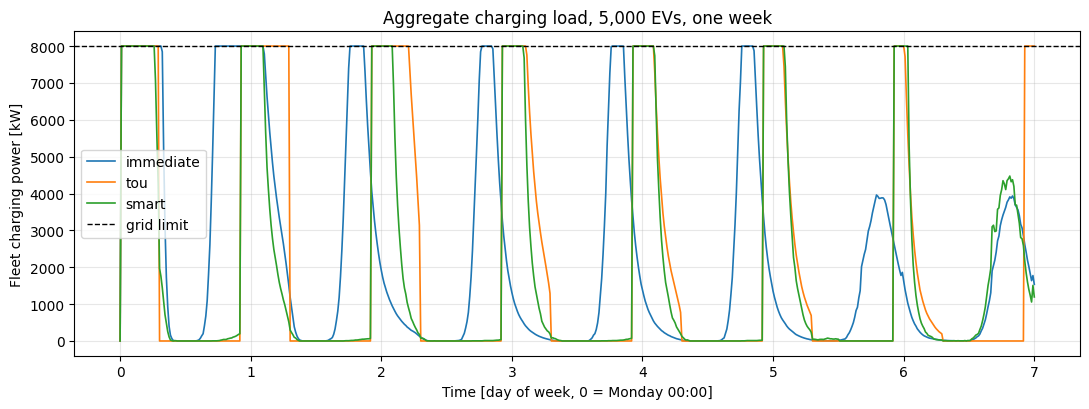

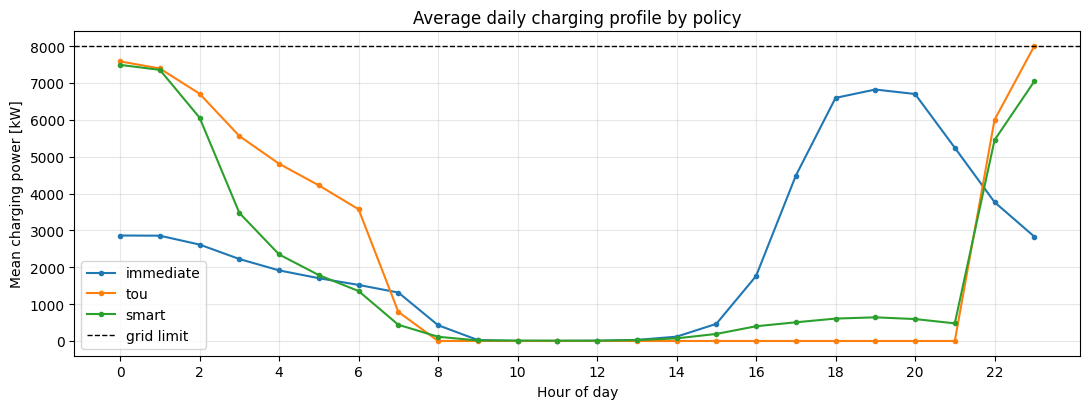

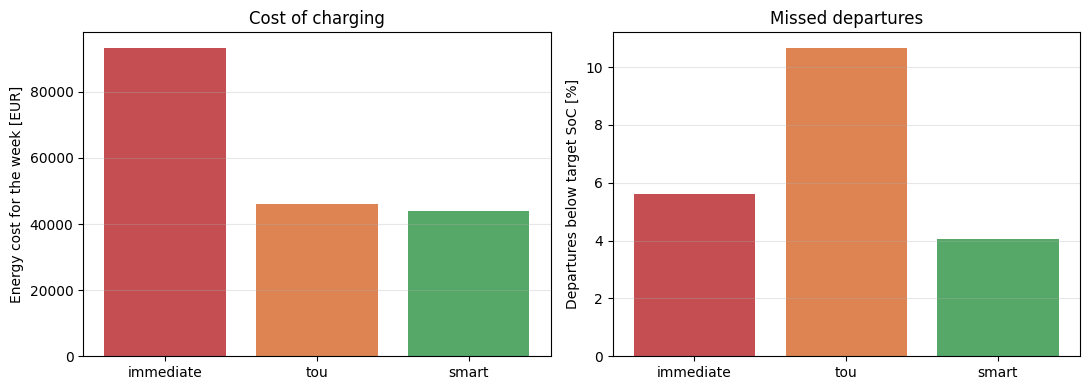

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for pol in POLICIES:
    _, df = results[pol]
    ax.plot(df.index.to_numpy() / 86400.0, df["total_p_charge_kw"].to_numpy(), label=pol, linewidth=1.2)
ax.axhline(GRID_LIMIT_KW, color="k", linestyle="--", linewidth=1, label="grid limit")
ax.set_xlabel("Time [day of week, 0 = Monday 00:00]")
ax.set_ylabel("Fleet charging power [kW]")
ax.set_title(f"Aggregate charging load, {N_EVS:,} EVs, one week")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.2))
for pol in POLICIES:
    _, df = results[pol]
    p = df["total_p_charge_kw"].to_numpy()
    hours = (df.index.to_numpy() / 3600.0) % 24.0
    prof = pd.Series(p).groupby(np.floor(hours).astype(int)).mean()
    ax.plot(prof.index, prof.values, marker="o", markersize=3, label=pol)
ax.axhline(GRID_LIMIT_KW, color="k", linestyle="--", linewidth=1, label="grid limit")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean charging power [kW]")
ax.set_title("Average daily charging profile by policy")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(list(POLICIES), summary["cost [EUR]"].to_numpy(), color=["#c44e52", "#dd8452", "#55a868"])
axes[0].set_ylabel("Energy cost for the week [EUR]")
axes[0].set_title("Cost of charging")
axes[0].grid(axis="y", alpha=0.3)
axes[1].bar(list(POLICIES), 100.0 * summary["share departing below target"].to_numpy(),
            color=["#c44e52", "#dd8452", "#55a868"])
axes[1].set_ylabel("Departures below target SoC [%]")
axes[1].set_title("Missed departures")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Reading the results

- **Immediate** charging starts every car at arrival, so the load sits in the evening peak
  (about 18:00 to 21:00) and the cars charge to 100 %. It has the highest energy use and the
  highest cost, because the evening price is the highest.
- **TOU** moves the charging into the cheap window (22:00 to 07:00). The cost falls by about half,
  but all cars start at the same time, so the grid limit is hit at 22:00 and many cars do not
  reach the target before they leave. That shows up as the largest unmet energy.
- **Smart** starts each car at its latest start time, or as soon as the price is cheap. It has the
  lowest cost and the fewest missed departures of the three in this run. The cheap-hour start
  still causes a wave at 22:00, so smart also spends many hours at the grid limit.

The deadline rule is only as good as its power assumption. The latest start time assumes each car
charges at full charger power. Try the deadline on its own (remove `| cheap` from the smart rule):
the cars then start between about 04:00 and 08:00, the requested power is far above the grid limit,
the proportional scaling cuts each car's power, and most departures are missed (about 85 % in this
population). A grid-aware deadline, which assumes a fair share of the limit, is the next step.

Set `GRID_LIMIT_KW` higher or lower to see the trade-off move. The metrics above are the ones to
compare: cost, missed departures and hours at the grid limit.

The model is deliberately simple: one trip per day, one charger per car, a single tariff,
and no charging at work or public chargers. Each of these can be added as a parameter
without changing the structure of `EVFleet`.

## Where to go next

- [06 - Large-scale vectorized fleet aggregation](06_vectorized_fleet_aggregation.ipynb):
  the built-in fleet adapters and the aggregation used in this notebook.
- [08 - BESS fleet with extra physics](08_fleet_bess_physics.ipynb): the same subclassing
  pattern applied to battery containers, with thermal and ageing states.
- 12 - DSO feeder with fleets (planned): hosting these EV charging loads on a pandapower
  feeder to check voltage and loading.